# Initialisation

In [1]:

from pulp import *
import numpy as np
from scipy.spatial.distance import cdist
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import time

# Version sans coûts variables

In [7]:
# version sans coûts variables
def generer_instance(n, x_max=1950, y_max=950, seed=None):
    if seed is not None:
        np.random.seed(seed)
    
    x_coords = np.random.randint(50, x_max, size=n)
    y_coords = np.random.randint(50, y_max, size=n)
    coords = np.column_stack((x_coords, y_coords))
    
    dist = np.round(cdist(coords, coords, metric='euclidean') * 100).astype(int)
    
    return coords.tolist(), dist.tolist()


In [12]:
#versiion sans coûts variables
n = 400

coords, dist = generer_instance(n)

print(f"Instance générée : {n} villes")
print(f"Coordonnées : {coords}")


Instance générée : 400 villes
Coordonnées : [[947, 219], [1911, 245], [1222, 729], [1856, 69], [864, 257], [1390, 650], [469, 459], [182, 260], [195, 667], [646, 435], [525, 133], [655, 778], [1136, 927], [1374, 129], [510, 88], [270, 661], [1545, 709], [203, 870], [456, 375], [1127, 588], [721, 904], [1612, 244], [1096, 661], [1084, 392], [372, 767], [845, 280], [590, 460], [1252, 380], [925, 224], [85, 724], [961, 404], [1169, 779], [1511, 487], [1042, 173], [1181, 605], [744, 67], [1035, 176], [1865, 76], [1532, 454], [674, 713], [1621, 883], [447, 348], [708, 303], [1214, 265], [1288, 353], [892, 747], [1318, 100], [404, 604], [579, 520], [424, 458], [1139, 646], [1088, 908], [1917, 497], [318, 542], [400, 365], [1143, 788], [233, 383], [927, 171], [1672, 250], [815, 298], [830, 306], [377, 276], [219, 447], [1139, 196], [522, 179], [1448, 581], [221, 180], [990, 900], [1479, 401], [651, 701], [1295, 741], [1708, 755], [980, 200], [479, 648], [1076, 280], [1927, 833], [1516, 393], 

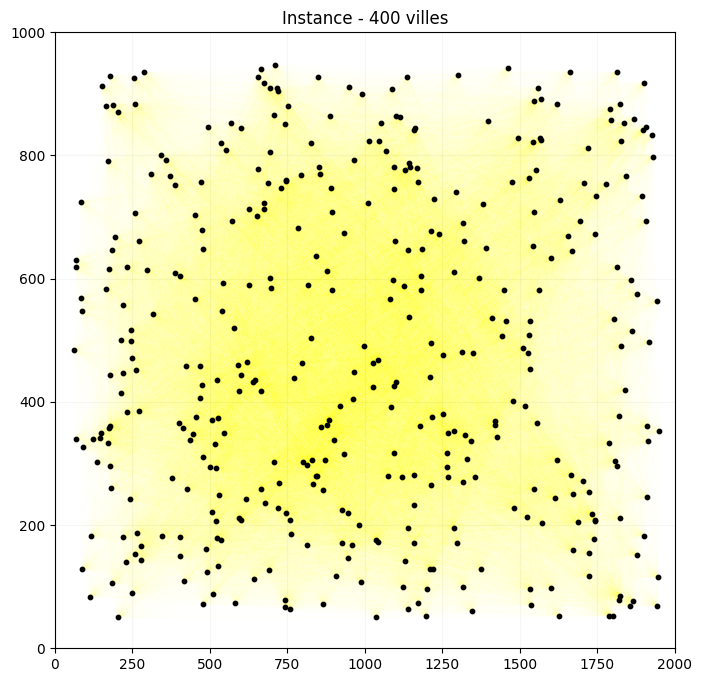

In [13]:
coords = np.array(coords)

segments = [coords[[i, j]] for i in range(n) for j in range(i + 1, n)]

fig, ax = plt.subplots(figsize=(8, 8))
ax.add_collection(LineCollection(segments, colors='yellow', linewidths=0.1, alpha=0.03))
ax.scatter(coords[:, 0], coords[:, 1], s=10, c='black', zorder=5)

ax.grid(True, alpha=0.1)
ax.set_title(f'Instance - {n} villes')
ax.set_xlim(0, 2000)
ax.set_ylim(0, 1000)
ax.set_aspect('auto')
plt.show()

# Version avec coûts variables

In [2]:
def generer_instance(
    n,
    x_max=1950,
    y_max=950,
    seed=None,
    pct_travaux=0.1,
    pct_interdites=0.05,
    coef_travaux_min=1.0,
    coef_travaux_max=2.0,
    coef_interdit_min=10000,
    coef_interdit_max=100000,
):
    if seed is not None:
        np.random.seed(seed)
    
    def normaliser_pourcentage(valeur):
        return valeur / 100 if valeur > 1 else valeur
    
    x_coords = np.random.randint(50, x_max, size=n)
    y_coords = np.random.randint(50, y_max, size=n)
    coords = np.column_stack((x_coords, y_coords))
    
    dist = np.round(cdist(coords, coords, metric='euclidean') * 100).astype(int)
    couts = dist.copy()
    
    aretes = [(i, j) for i in range(n) for j in range(i + 1, n)]
    total_aretes = len(aretes)
    if total_aretes == 0:
        return coords.tolist(), couts.tolist(), [], []
    
    pct_travaux = normaliser_pourcentage(pct_travaux)
    pct_interdites = normaliser_pourcentage(pct_interdites)
    
    nb_travaux = min(total_aretes, int(round(pct_travaux * total_aretes)))
    nb_interdites = min(total_aretes - nb_travaux, int(round(pct_interdites * total_aretes)))
    
    indices = np.arange(total_aretes)
    aretes_travaux = []
    aretes_interdites = []
    
    if nb_travaux > 0:
        indices_travaux = np.random.choice(indices, size=nb_travaux, replace=False)
        for idx in indices_travaux:
            i, j = aretes[idx]
            coef = np.random.uniform(coef_travaux_min, coef_travaux_max)
            valeur = int(round(dist[i, j] * coef))
            couts[i, j] = valeur
            couts[j, i] = valeur
            aretes_travaux.append((i, j))
        indices = np.setdiff1d(indices, indices_travaux, assume_unique=False)
    
    if nb_interdites > 0:
        indices_interdites = np.random.choice(indices, size=nb_interdites, replace=False)
        for idx in indices_interdites:
            i, j = aretes[idx]
            penalite = int(round(np.random.uniform(coef_interdit_min, coef_interdit_max)))
            valeur = dist[i, j] + penalite
            couts[i, j] = valeur
            couts[j, i] = valeur
            aretes_interdites.append((i, j))
    
    return coords.tolist(), couts.tolist(), aretes_travaux, aretes_interdites


In [3]:
n = 20
coords, dist, aretes_travaux, aretes_interdites = generer_instance(
    n=n,
    pct_travaux=0.05,
    pct_interdites=0.02,
    coef_travaux_min=1.0,
    coef_travaux_max=2.0,
    coef_interdit_min=10000,
    coef_interdit_max=100000,
    seed=None,
)

print(f"Instance générée : {n} villes")
print(f"Nombre total d'arêtes : {n * (n - 1) // 2}")
print(f"Nombre d'arêtes en travaux : {len(aretes_travaux)}")
print(f"Nombre d'arêtes interdites : {len(aretes_interdites)}")
print(f"Coordonnées : {coords}")


Instance générée : 20 villes
Nombre total d'arêtes : 190
Nombre d'arêtes en travaux : 10
Nombre d'arêtes interdites : 4
Coordonnées : [[347, 115], [1847, 299], [399, 353], [938, 389], [676, 232], [1562, 380], [209, 571], [940, 319], [819, 74], [415, 466], [1288, 402], [836, 488], [143, 461], [1463, 166], [571, 411], [309, 543], [704, 493], [819, 351], [262, 219], [881, 100]]


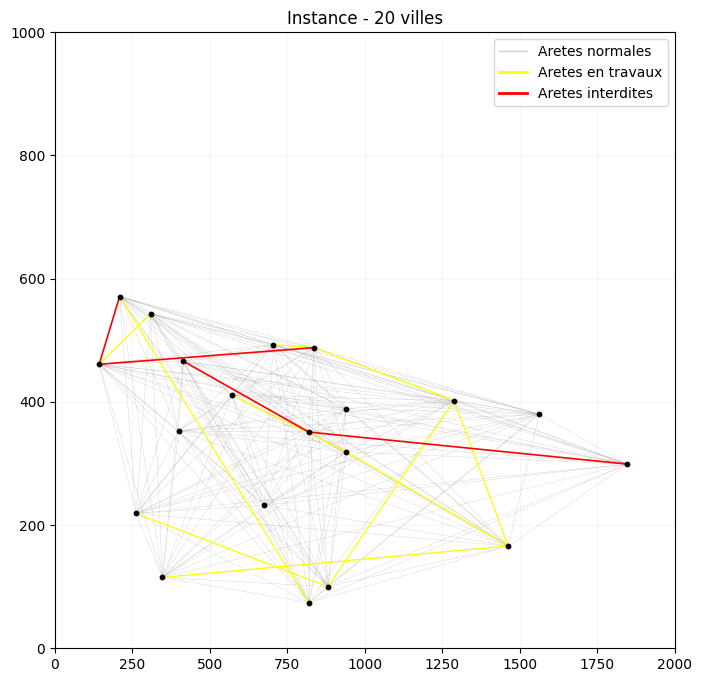

In [4]:
coords = np.array(coords)
from matplotlib.lines import Line2D

all_segments = [coords[[i, j]] for i in range(n) for j in range(i + 1, n)]
segments_travaux = [coords[[i, j]] for i, j in aretes_travaux]
segments_interdites = [coords[[i, j]] for i, j in aretes_interdites]

fig, ax = plt.subplots(figsize=(8, 8))
ax.add_collection(LineCollection(all_segments, colors='grey', linewidths=0.1, alpha=1, zorder=1))
if segments_travaux:
    ax.add_collection(LineCollection(segments_travaux, colors='yellow', linewidths=0.9, alpha=1, zorder=2))
if segments_interdites:
    ax.add_collection(LineCollection(segments_interdites, colors='red', linewidths=1.2, alpha=1, zorder=3))

ax.scatter(coords[:, 0], coords[:, 1], s=10, c='black', zorder=4)

legend_elements = [
    Line2D([0], [0], color='lightgray', lw=1, label='Aretes normales'),
    Line2D([0], [0], color='yellow', lw=2, label='Aretes en travaux'),
    Line2D([0], [0], color='red', lw=2, label='Aretes interdites'),
]
ax.legend(handles=legend_elements, loc='upper right')

ax.grid(True, alpha=0.1)
ax.set_title(f'Instance - {n} villes')
ax.set_xlim(0, 2000)
ax.set_ylim(0, 1000)
ax.set_aspect('auto')
plt.show()


Statut : Optimal
Coût optimal : 452204.00
Tournée : [0, 4, 8, 19, 13, 1, 5, 10, 7, 3, 11, 17, 16, 14, 2, 9, 6, 15, 12, 18, 0]
Temps de résolution : 40.8783 s


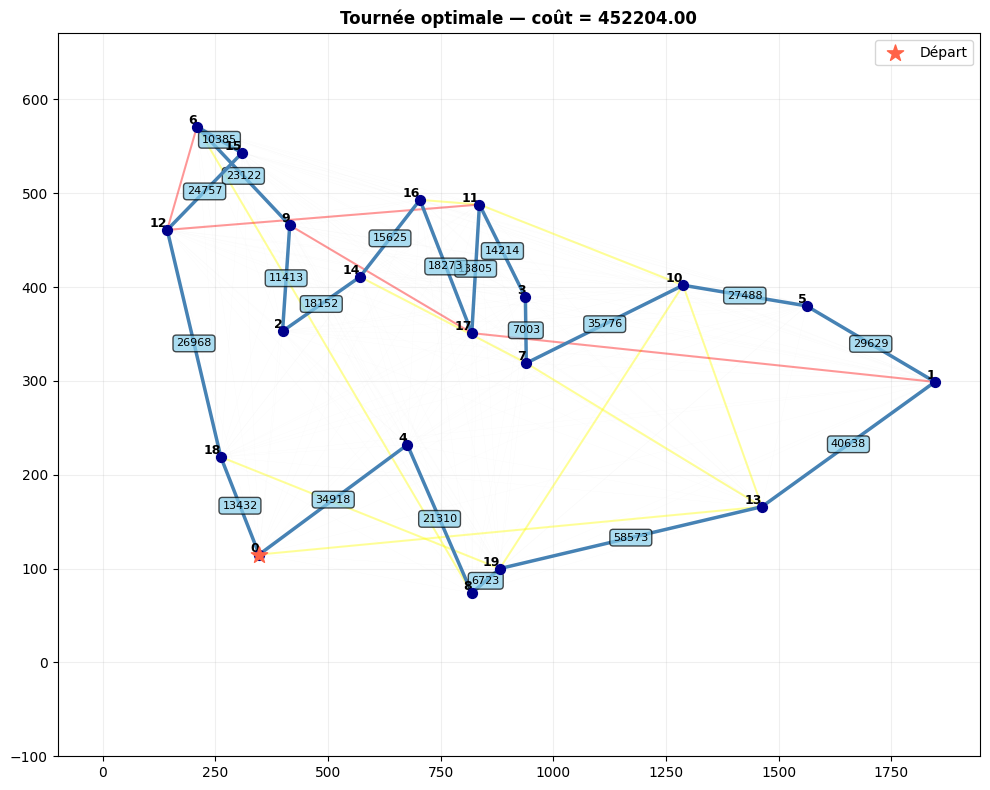

In [5]:
def resoudre_tsp_plne(couts, coords=None, aretes_travaux=None, aretes_interdites=None):
    """
    Résout le TSP avec coûts variables (travaux et arêtes interdites).
    
    Paramètres:
    - couts: matrice de coûts (peut contenir des surcoûts pour travaux/interdits)
    - coords: coordonnées des villes (optionnel, pour l'affichage)
    - aretes_travaux: liste des arêtes en travaux
    - aretes_interdites: liste des arêtes interdites
    
    Retourne:
    - tournee: liste des indices des villes dans l'ordre de visite
    - cout: coût total optimal
    - duree: temps de résolution en secondes
    """
    n = len(couts)
    villes = range(n)

    prob = LpProblem("TSP_Couts_Variables", LpMinimize)

    # --- Variables de décision ---
    x = LpVariable.dicts("x", (villes, villes), cat="Binary")
    p = LpVariable.dicts("p", range(1, n), lowBound=1, upBound=n - 1, cat="Continuous")

    # --- Fonction objectif ---
    prob += lpSum(couts[i][j] * x[i][j] for i in villes for j in villes if i != j)

    # --- Contrainte C1 : chaque ville a exactement un prédécesseur et un successeur ---
    for i in villes:
        prob += lpSum(x[i][j] for j in villes if j != i) == 1
        prob += lpSum(x[j][i] for j in villes if j != i) == 1

    # --- Contrainte C2 : élimination des sous-tours (Miller-Tucker-Zemlin) ---
    for i in range(1, n):
        for j in range(1, n):
            if i != j:
                prob += p[i] - p[j] + n * x[i][j] <= n - 1

    # --- Résolution ---
    debut = time.time()
    prob.solve(PULP_CBC_CMD(msg=0))
    duree = time.time() - debut

    if LpStatus[prob.status] != "Optimal":
        print(f"Statut du solveur : {LpStatus[prob.status]}")
        return None, None, duree

    cout = value(prob.objective)

    # Reconstruire la tournée
    tournee = [0]
    ville_courante = 0
    for _ in range(n - 1):
        for j in villes:
            if j != ville_courante and value(x[ville_courante][j]) > 0.5:
                tournee.append(j)
                ville_courante = j
                break

    print(f"Statut : {LpStatus[prob.status]}")
    print(f"Coût optimal : {cout:.2f}")
    print(f"Tournée : {tournee + [tournee[0]]}")
    print(f"Temps de résolution : {duree:.4f} s")

    return tournee, cout, duree


def afficher_tournee(coords, tournee, dist, couts=None, aretes_travaux=None, aretes_interdites=None, cout=None):
    """
    Affiche la tournée avec les coûts variables si disponibles.
    
    Paramètres:
    - coords: coordonnées des villes
    - tournee: tournée à afficher
    - dist: matrice de distances euclidiennes (pour les labels)
    - couts: matrice de coûts (optionnel)
    - aretes_travaux: liste des arêtes en travaux
    - aretes_interdites: liste des arêtes interdites
    - cout: coût total de la tournée
    """
    titre = "Tournée optimale"
    if cout is not None:
        titre += f" — coût = {cout:.2f}"
    
    fig, ax = plt.subplots(figsize=(10, 8))
    
    # Tracer le graphe complet en gris léger
    coords_np = np.array(coords)
    all_segments = [coords_np[[i, j]] for i in range(len(coords)) for j in range(i + 1, len(coords))]
    ax.add_collection(LineCollection(all_segments, colors='lightgray', linewidths=0.1, alpha=0.2))
    
    # Surcharger avec les arêtes en travaux et interdites
    if aretes_travaux:
        segments_travaux = [coords_np[[i, j]] for i, j in aretes_travaux]
        ax.add_collection(LineCollection(segments_travaux, colors='yellow', linewidths=1.5, alpha=0.4))
    
    if aretes_interdites:
        segments_interdites = [coords_np[[i, j]] for i, j in aretes_interdites]
        ax.add_collection(LineCollection(segments_interdites, colors='red', linewidths=1.5, alpha=0.4))
    
    # Tracer la tournée
    for k in range(len(tournee)):
        i = tournee[k]
        j = tournee[(k + 1) % len(tournee)]
        ax.plot([coords_np[i, 0], coords_np[j, 0]],
               [coords_np[i, 1], coords_np[j, 1]],
               color="steelblue", linewidth=2.5, zorder=3)
        
        mid_x = (coords_np[i, 0] + coords_np[j, 0]) / 2
        mid_y = (coords_np[i, 1] + coords_np[j, 1]) / 2
        distance = dist[i][j]
        ax.text(mid_x, mid_y, f'{distance:.0f}', fontsize=8, ha='center', va='center',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='skyblue', alpha=0.7))
    
    # Annoter les villes
    for i, (x, y) in enumerate(coords_np):
        ax.scatter(x, y, c="darkblue", s=50, zorder=5)
        ax.annotate(f"{i}", (x, y), fontsize=9, ha='right', va='bottom', fontweight='bold')
    
    # Marquer le départ
    ax.scatter([coords_np[0, 0]], [coords_np[0, 1]], c="tomato", s=150, zorder=6, marker='*', label="Départ")
    
    ax.set_title(titre, fontsize=12, fontweight='bold')
    ax.set_xlim(-100, max(coords_np[:, 0]) + 100)
    ax.set_ylim(-100, max(coords_np[:, 1]) + 100)
    ax.grid(True, alpha=0.2)
    ax.legend()
    plt.tight_layout()
    plt.show()


# Résoudre le problème
tournee, cout, duree = resoudre_tsp_plne(dist, coords, aretes_travaux, aretes_interdites)

if tournee is not None:
    afficher_tournee(coords, tournee, dist, couts=dist, aretes_travaux=aretes_travaux, 
                    aretes_interdites=aretes_interdites, cout=cout)


Résolution exacte pour n=10
Instance 1/3... Statut : Optimal
Coût optimal : 460559.00
Tournée : [0, 3, 7, 8, 6, 1, 4, 9, 2, 5, 0]
Temps de résolution : 0.2014 s
OK - 0.2014s
Instance 2/3... Statut : Optimal
Coût optimal : 425026.00
Tournée : [0, 3, 1, 6, 5, 7, 2, 4, 8, 9, 0]
Temps de résolution : 1.2870 s
OK - 1.2870s
Instance 3/3... Statut : Optimal
Coût optimal : 423703.00
Tournée : [0, 1, 8, 7, 2, 6, 5, 4, 9, 3, 0]
Temps de résolution : 0.9111 s
OK - 0.9111s

Résolution exacte pour n=15
Instance 1/3... Statut : Optimal
Coût optimal : 441181.00
Tournée : [0, 4, 1, 13, 6, 8, 3, 11, 5, 7, 2, 14, 9, 12, 10, 0]
Temps de résolution : 3.0812 s
OK - 3.0812s
Instance 2/3... Statut : Optimal
Coût optimal : 533389.00
Tournée : [0, 1, 12, 9, 8, 14, 4, 7, 2, 6, 5, 13, 11, 3, 10, 0]
Temps de résolution : 14.8108 s
OK - 14.8108s
Instance 3/3... Statut : Optimal
Coût optimal : 507124.00
Tournée : [0, 3, 11, 9, 13, 8, 4, 12, 10, 6, 5, 2, 7, 1, 14, 0]
Temps de résolution : 17.8599 s
OK - 17.8599s

R

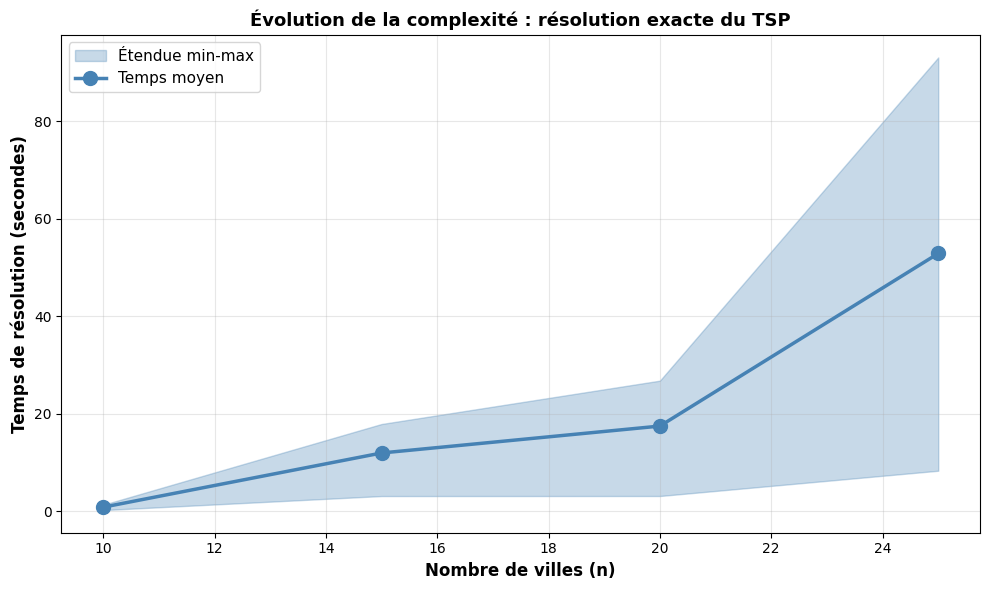


ANALYSE
• Croissance exponentielle observée : temps → infini rapidement
• Au-delà de n=25, résolution exacte devient impraticable
• Nécessité d'algorithmes approchés/métaheuristiques pour:
  - Instances réalistes (n > 50)
  - Optimisation en temps acceptable


In [9]:
import pandas as pd

tailles_n = [10, 15, 20, 25]
nb_instances_par_taille = 3

resultats = []

for n in tailles_n:
    temps_par_instance = []
    
    print(f"\n{'='*50}")
    print(f"Résolution exacte pour n={n}")
    print(f"{'='*50}")
    
    for run in range(nb_instances_par_taille):
        coords, couts, aretes_travaux, aretes_interdites = generer_instance(
            n=n,
            pct_travaux=0.05,
            pct_interdites=0.02,
            seed=42 + run
        )
        
        print(f"Instance {run+1}/{nb_instances_par_taille}...", end=" ", flush=True)
        tournee, cout, duree = resoudre_tsp_plne(couts, coords, aretes_travaux, aretes_interdites)
        
        if tournee is not None:
            print(f"OK - {duree:.4f}s")
            temps_par_instance.append(duree)
        else:
            print("Échec")
    
    if temps_par_instance:
        temps_moyen = np.mean(temps_par_instance)
        temps_min = np.min(temps_par_instance)
        temps_max = np.max(temps_par_instance)
        
        resultats.append({
            'n': n,
            'Temps moyen (s)': f"{temps_moyen:.4f}",
            'Temps min (s)': f"{temps_min:.4f}",
            'Temps max (s)': f"{temps_max:.4f}",
            'Arêtes': n * (n - 1) // 2
        })

df_resultats = pd.DataFrame(resultats)
print("\n" + "="*60)
print("RÉSULTATS - Complexité de la résolution exacte")
print("="*60)
print(df_resultats.to_string(index=False))

# Extraction des valeurs numériques pour le graphique
temps_moyens = [float(r['Temps moyen (s)']) for r in resultats]
temps_mins = [float(r['Temps min (s)']) for r in resultats]
temps_maxs = [float(r['Temps max (s)']) for r in resultats]
n_values = [r['n'] for r in resultats]

fig, ax = plt.subplots(figsize=(10, 6))
ax.fill_between(n_values, temps_mins, temps_maxs, alpha=0.3, color='steelblue', label='Étendue min-max')
ax.plot(n_values, temps_moyens, 'o-', linewidth=2.5, markersize=10, color='steelblue', label='Temps moyen')
ax.set_xlabel('Nombre de villes (n)', fontsize=12, fontweight='bold')
ax.set_ylabel('Temps de résolution (secondes)', fontsize=12, fontweight='bold')
ax.set_title('Évolution de la complexité : résolution exacte du TSP', fontsize=13, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

print("\n" + "="*60)
print("ANALYSE")
print("="*60)
print("• Croissance exponentielle observée : temps → infini rapidement")
print("• Au-delà de n=25, résolution exacte devient impraticable")
print("• Nécessité d'algorithmes approchés/métaheuristiques pour:")
print("  - Instances réalistes (n > 50)")
print("  - Optimisation en temps acceptable")
print("="*60)